<a href="https://colab.research.google.com/github/Haripriya172406/ResQbridge/blob/main/Copy_of_Frozen_lake_Q_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install gymnasium numpy matplotlib

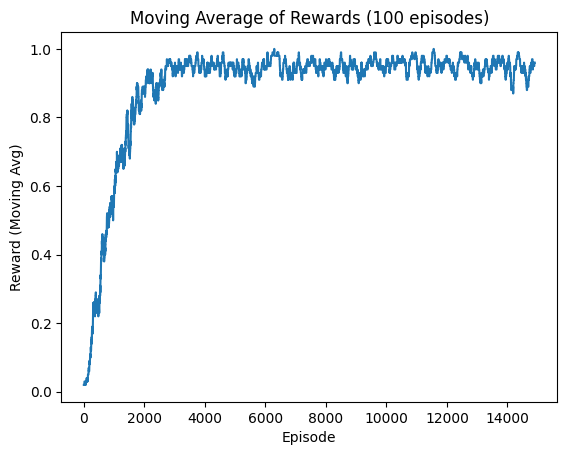

In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pickle


def run(episodes, render=False):

    # Create FrozenLake environment
    env = gym.make(
        "FrozenLake-v1",
        map_name="4x4",
        is_slippery=False,
        render_mode="human" if render else None
    )

    # Create Q-table
    q = np.zeros((
        env.observation_space.n,
        env.action_space.n
    ))

    # Hyperparameters
    learning_rate = 0.8
    discount = 0.95
    epsilon = 1.0
    epsilon_min = 0.05
    epsilon_decay = 0.999

    rng = np.random.default_rng()
    rewards_per_episode = []

    # Train the agent
    for i in range(episodes):

        state, _ = env.reset()
        done = False
        total_reward = 0

        while not done:

            # Exploration or exploitation
            if rng.random() < epsilon:
                action = env.action_space.sample()
            else:
                action = np.argmax(q[state])

            # Perform action
            next_state, reward, terminated, truncated, _ = (
                env.step(action)
            )

            done = terminated or truncated

            # Update Q-value
            q[state, action] += learning_rate * (
                reward
                + discount * np.max(q[next_state])
                - q[state, action]
            )

            # Update state and reward
            state = next_state
            total_reward += reward

        rewards_per_episode.append(total_reward)

        # Reduce exploration gradually
        epsilon = max(
            epsilon * epsilon_decay,
            epsilon_min
        )

    env.close()

    # Plot moving average of rewards
    moving_avg = np.convolve(
        rewards_per_episode,
        np.ones(100) / 100,
        mode="valid"
    )

    plt.plot(moving_avg)
    plt.title("Moving Average of Rewards (100 episodes)")
    plt.xlabel("Episode")
    plt.ylabel("Reward (Moving Avg)")
    plt.savefig("frozen_lake_4x4_learning.png")
    plt.show()

    # Save Q-table
    with open("frozen_lake_4x4_qtable.pkl", "wb") as f:
        pickle.dump(q, f)


if __name__ == "__main__":
    run(15000)

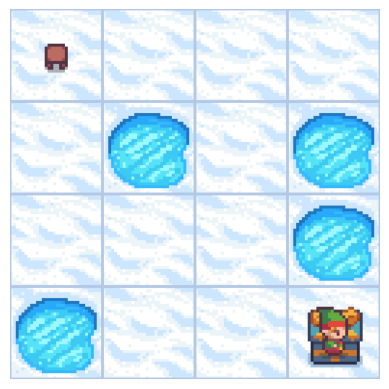

In [ ]:
from IPython.display import clear_output
import matplotlib.pyplot as plt
import time
import pickle
import gymnasium as gym
import numpy as np


def run_final_episode_colab(q_table):

    # Create environment for visualization
    env = gym.make(
        "FrozenLake-v1",
        map_name="4x4",
        is_slippery=False,
        render_mode="rgb_array"
    )

    state, _ = env.reset()
    done = False

    print("Running final episode (rendered):")

    while not done:

        # Select the best learned action
        action = np.argmax(q_table[state])

        # Perform the action
        next_state, reward, terminated, truncated, _ = (
            env.step(action)
        )

        done = terminated or truncated
        state = next_state

        # Display the current frame
        frame = env.render()

        clear_output(wait=True)
        plt.imshow(frame)
        plt.axis("off")
        plt.show()

        time.sleep(0.5)

    env.close()


# Load the trained Q-table
with open("frozen_lake_4x4_qtable.pkl", "rb") as f:
    q_table = pickle.load(f)

# Run the final episode
run_final_episode_colab(q_table)

In [ ]:

import pickle
import json
from IPython.display import HTML, display

# Load your trained Q-table
with open("frozen_lake_4x4_qtable.pkl", "rb") as f:
    q_table = pickle.load(f)

# Convert the Q-table to a format JavaScript can use
q_json = json.dumps(q_table.tolist())

html = r"""
<div id="frozen-game" style="
    max-width:650px; margin:auto; padding:22px;
    border-radius:20px; background:#101827; color:white;
    font-family:Arial,sans-serif; text-align:center;">

  <h2 style="margin:0 0 6px;color:#a5f3fc;">❄️ FrozenLake AI Challenge</h2>
  <p style="color:#cbd5e1;margin-top:0;">
    Help the AI explorer reach the goal safely!
  </p>

  <div style="display:flex;justify-content:center;gap:8px;
              flex-wrap:wrap;margin:16px 0;">
    <span style="background:#243449;padding:8px 12px;border-radius:9px;">
      📍 State: <b id="state">0</b>
    </span>
    <span style="background:#243449;padding:8px 12px;border-radius:9px;">
      👣 Moves: <b id="moves">0</b>
    </span>
    <span style="background:#243449;padding:8px 12px;border-radius:9px;">
      🧠 Mode: <b>Trained AI</b>
    </span>
  </div>

  <div id="board" style="
      display:grid;grid-template-columns:repeat(4,minmax(0,1fr));
      gap:7px;max-width:390px;margin:20px auto;">
  </div>

  <div id="status" role="status" style="
      min-height:26px;color:#a5f3fc;font-weight:bold;margin:12px;">
    Ready! Press Start AI.
  </div>

  <div style="display:flex;justify-content:center;gap:10px;flex-wrap:wrap;">
    <button id="start" style="background:#16a34a;color:white;">
      ▶ Start AI
    </button>
    <button id="step" style="background:#2563eb;color:white;">
      ➜ Step
    </button>
    <button id="reset" style="background:#475569;color:white;">
      ↻ Reset
    </button>
  </div>

  <p style="color:#cbd5e1;font-size:12px;margin-top:18px;">
    🟦 Start &nbsp; ❄️ Safe ice &nbsp; 🕳️ Hole &nbsp; 🏁 Goal
  </p>
</div>

<style>
#frozen-game button {
  border:0; border-radius:10px; padding:11px 17px;
  cursor:pointer; font-size:14px; font-weight:bold;
}
#frozen-game button:disabled {
  opacity:.45; cursor:not-allowed;
}
#frozen-game .tile {
  aspect-ratio:1; border-radius:12px; display:flex;
  flex-direction:column; justify-content:center; align-items:center;
  font-size:27px; position:relative; box-sizing:border-box;
  border:2px solid transparent; transition:background .2s;
}
#frozen-game .tile small {font-size:10px;margin-top:3px;}
#frozen-game .safe {background:#dbeafe;color:#1e3a5f;}
#frozen-game .hole {background:#fecaca;color:#7f1d1d;}
#frozen-game .goal {background:#bbf7d0;color:#14532d;}
#frozen-game .current {
  border:3px solid #facc15;
  box-shadow:0 0 14px #facc1580;
}
#frozen-game .player {font-size:32px;line-height:1.1;}
</style>

<script>
(() => {
  const root = document.getElementById("frozen-game");
  if (!root || root.dataset.ready) return;
  root.dataset.ready = "yes";

  const Q = __QTABLE__;
  const holes = [5, 7, 11, 12];
  const board = root.querySelector("#board");
  const stateLabel = root.querySelector("#state");
  const movesLabel = root.querySelector("#moves");
  const status = root.querySelector("#status");
  const startBtn = root.querySelector("#start");
  const stepBtn = root.querySelector("#step");
  const resetBtn = root.querySelector("#reset");

  let position = 0;
  let moves = 0;
  let finished = false;
  let running = false;
  let runId = 0;

  const tiles = [];

  for (let i = 0; i < 16; i++) {
    const tile = document.createElement("div");
    tile.className = "tile safe";

    const label = document.createElement("small");
    tile.appendChild(label);
    board.appendChild(tile);
    tiles.push({tile, label});
  }

  function render() {
    tiles.forEach(({tile, label}, i) => {
      tile.className = "tile";
      let symbol = "❄️";
      let name = "Frozen";

      if (i === 0) {
        symbol = "🟦";
        name = "Start";
      }
      if (holes.includes(i)) {
        tile.classList.add("hole");
        symbol = "🕳️";
        name = "Hole";
      } else if (i === 15) {
        tile.classList.add("goal");
        symbol = "🏁";
        name = "Goal";
      } else {
        tile.classList.add("safe");
      }

      tile.replaceChildren();
      if (i === position) {
        tile.classList.add("current");
        const player = document.createElement("div");
        player.className = "player";
        player.textContent = "🧑‍🚀";
        tile.appendChild(player);
      } else {
        const icon = document.createElement("div");
        icon.textContent = symbol;
        tile.appendChild(icon);
      }

      label.textContent = name;
      tile.appendChild(label);
    });

    stateLabel.textContent = position;
    movesLabel.textContent = moves;
  }

  function finish(message) {
    finished = true;
    running = false;
    status.textContent = message;
    startBtn.disabled = true;
    stepBtn.disabled = true;
  }

  async function takeStep() {
    if (finished) return false;

    // Q-learning action order: Left, Down, Right, Up.
    const action = Q[position].indexOf(Math.max(...Q[position]));

    const row = Math.floor(position / 4);
    const col = position % 4;

    let next = position;
    if (action === 0 && col > 0) next--;
    if (action === 1 && row < 3) next += 4;
    if (action === 2 && col < 3) next++;
    if (action === 3 && row > 0) next -= 4;

    position = next;
    moves++;
    render();

    if (holes.includes(position)) {
      finish("Oh no! The explorer fell into a hole. Reset to try again.");
      return false;
    }

    if (position === 15) {
      finish("🎉 Success! The AI reached the goal safely!");
      return false;
    }

    status.textContent = "AI is moving... State " + position;
    if (moves >= 100) {
      finish("Stopped after 100 moves. Reset and inspect the learned policy.");
      return false;
    }

    return true;
  }

  startBtn.addEventListener("click", async () => {
    if (running || finished) return;

    running = true;
    startBtn.disabled = true;
    stepBtn.disabled = true;
    const myRun = ++runId;

    while (running && !finished && myRun === runId) {
      const shouldContinue = await takeStep();
      if (!shouldContinue) break;
      await new Promise(resolve => setTimeout(resolve, 650));
    }

    running = false;
    if (!finished) {
      startBtn.disabled = false;
      stepBtn.disabled = false;
    }
  });

  stepBtn.addEventListener("click", () => {
    if (!finished && !running) takeStep();
  });

  resetBtn.addEventListener("click", () => {
    runId++;
    running = false;
    position = 0;
    moves = 0;
    finished = false;
    startBtn.disabled = false;
    stepBtn.disabled = false;
    status.textContent = "Game reset! Press Start AI.";
    render();
  });

  render();
})();
</script>
"""

html = html.replace("__QTABLE__", q_json)
display(HTML(html))
